# TMPv, TMPt, and Mult data understanding

This notebook uses OpenCV to inventory all three video representations, test frame-index synchronization, and display the same timestamp side by side.

> Matching FPS, frame count, duration, resolution, and decodable frame indices establishes **structural synchronization**. Without shared timecodes or event registration, it cannot prove sub-frame-perfect alignment.

In [ ]:
from pathlib import Path
import cv2
import numpy as np
from html import escape
from IPython.display import HTML, Image, display


Dataset: /Volumes/1TB/Dataset


In [6]:

# Turn a list of dictionaries into an inline HTML table.
def show_table(records, exclude=()):
    records = list(records)
    if not records:
        return display(HTML("<em>No rows</em>"))
    columns = [key for key in records[0] if key not in exclude]
    def fmt(value):
        if isinstance(value, float):
            return f"{value:.6f}"
        return str(value)
    head = "".join(f"<th>{escape(str(c))}</th>" for c in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{escape(fmt(row[c]))}</td>" for c in columns
    ) + "</tr>" for row in records)
    display(HTML(f"<div style='overflow-x:auto'><table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>"))

# Jupyter can start in src/. Go up one level in that case.
root = Path.cwd().resolve()
if root.name == "src":
    root = root.parent
candidates = [root / "Dataset", root.parent / "Dataset", Path("/Volumes/1TB/Dataset")]
# Use the first existing directory, starting with the project-local Dataset.
DATASET_DIR = next((p for p in candidates if p.is_dir()), None)
if DATASET_DIR is None:
    raise FileNotFoundError("Set DATASET_DIR to the directory containing TMPv, TMPt, and Mult.")

SOURCES = {
    "TMPv": (DATASET_DIR / "TMPv", "*_TMPv.mp4"),
    "TMPt": (DATASET_DIR / "TMPt", "*_TMPt.mp4"),
    "Mult": (DATASET_DIR / "Mult", "*_TMPt_Multiplied.mp4"),
}
print("Dataset:", DATASET_DIR.resolve())


Dataset: /Volumes/1TB/Dataset


## Video inventory and parameters

Every file is inspected for frame rate, frame count, duration, image resolution, aspect ratio, codec, and size.

In [7]:
# The filename prefix is the shared recording ID across all three folders.
def record_id(path):
    return path.stem.split("_", 1)[0]

def codec_name(value):
    # FourCC packs four codec characters into one integer. Read one byte at a time.
    value = int(value)
    return "".join(chr((value >> (8 * i)) & 255) for i in range(4)).strip("\\x00")

def inspect_video(path, representation):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {path}")
    try:
        # Read the video metadata from OpenCV. FPS is the nominal frames per second.
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(round(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
        width = int(round(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
        height = int(round(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
        return {
            "recording": record_id(path), "representation": representation,
            "fps": fps, "frame_count": count,
            # Estimate duration from the reported frame count and nominal FPS.
            "duration_s": count / fps if fps else np.nan,
            "width": width, "height": height,
            "resolution": f"{width} x {height}",
            "aspect_ratio": width / height if height else np.nan,
            "codec": codec_name(cap.get(cv2.CAP_PROP_FOURCC)),
            "size_mb": path.stat().st_size / 1024**2, "path": path,
        }
    finally:
        # Close the video handle even if an error occurs.
        cap.release()

rows = []
for representation, (folder, pattern) in SOURCES.items():
    # Skip macOS ._ sidecar files, which are not videos.
    paths = sorted(p for p in folder.glob(pattern) if not p.name.startswith("._"))
    if not paths:
        raise FileNotFoundError(f"No {representation} files found in {folder}")
    rows += [inspect_video(p, representation) for p in paths]

metadata = sorted(rows, key=lambda r: (r["recording"], r["representation"]))
show_table(metadata, exclude={"path"})


recording,representation,fps,frame_count,duration_s,width,height,resolution,aspect_ratio,codec,size_mb
GX010041,Mult,239.760240,16459,68.647746,1920,1080,1920 x 1080,1.777778,h264,44.417297
GX010041,TMPt,239.760240,16459,68.647746,1920,1080,1920 x 1080,1.777778,h264,970.747631
GX010041,TMPv,239.760240,16459,68.647746,1920,1080,1920 x 1080,1.777778,h264,22.120502
GX010044,Mult,239.760240,4239,17.680163,1920,1080,1920 x 1080,1.777778,h264,3.228844
GX010044,TMPt,239.760240,4239,17.680163,1920,1080,1920 x 1080,1.777778,h264,89.458974
GX010044,TMPv,239.760240,4239,17.680163,1920,1080,1920 x 1080,1.777778,h264,2.204566
GX010047,Mult,239.760240,3027,12.625113,1920,1080,1920 x 1080,1.777778,h264,3.822199
GX010047,TMPt,239.760240,3027,12.625113,1920,1080,1920 x 1080,1.777778,h264,129.506158
GX010047,TMPv,239.760240,3027,12.625113,1920,1080,1920 x 1080,1.777778,h264,2.258166
GX010048,Mult,239.760240,14479,60.389496,1920,1080,1920 x 1080,1.777778,h264,20.870197


In [8]:
# Summarize each representation across all recordings.
summary = []
for representation in SOURCES:
    group = [r for r in metadata if r["representation"] == representation]
    summary.append({
        "representation": representation, "videos": len(group),
        "fps_values": sorted({r["fps"] for r in group}),
        "frame_count_range": f"{min(r['frame_count'] for r in group)}–{max(r['frame_count'] for r in group)}",
        "duration_range_s": f"{min(r['duration_s'] for r in group):.3f}–{max(r['duration_s'] for r in group):.3f}",
        "resolutions": sorted({r["resolution"] for r in group}),
        "codecs": sorted({r["codec"] for r in group}),
    })
show_table(summary)


representation,videos,fps_values,frame_count_range,duration_range_s,resolutions,codecs
TMPv,12,[239.76023976023976],2513–16459,10.481–68.648,['1920 x 1080'],['h264']
TMPt,12,[239.76023976023976],2513–16459,10.481–68.648,['1920 x 1080'],['h264']
Mult,12,[239.76023976023976],2513–16459,10.481–68.648,['1920 x 1080'],['h264']


Since the video player runs the recordings in 30fps, in the player it will go much longer then 68 seconds :- )

## Synchronization check

For each recording, all three representations must be present and have equal FPS, frame count, duration, and resolution. The first, middle, and last frames are also decoded to detect truncation.

In [9]:
def decodes(path, index):
    cap = cv2.VideoCapture(str(path))
    try:
        # Seek by zero-based frame index, then try decoding that frame.
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        ok, frame = cap.read()
        return bool(ok and frame is not None)
    finally:
        cap.release()

def check_sync(recording, group):
    all_present = {r["representation"] for r in group} == set(SOURCES)
    # Use small tolerances for floating-point FPS and duration comparisons.
    same_fps = len(group) == 3 and np.allclose([r["fps"] for r in group], group[0]["fps"], atol=1e-6, rtol=0)
    same_count = len(group) == 3 and len({r["frame_count"] for r in group}) == 1
    same_size = len(group) == 3 and len({(r["width"], r["height"]) for r in group}) == 1
    same_duration = len(group) == 3 and np.allclose(
        [r["duration_s"] for r in group], group[0]["duration_s"], atol=1e-3, rtol=0
    )
    readable = False
    if all_present and same_count:
        n = group[0]["frame_count"]
        # Spot-check the start, middle, and end of each stream.
        indices = sorted(set([0, n // 2, n - 1]))
        readable = all(decodes(r["path"], i) for r in group for i in indices)
    return {
        "recording": recording,
        "all_3_present": all_present, "same_fps": same_fps,
        "same_frame_count": same_count, "same_resolution": same_size,
        "same_duration": same_duration, "sample_frames_decodable": readable,
        "structurally_synchronized": all_present and same_fps and same_count
            and same_size and same_duration and readable,
    }

recordings = sorted({r["recording"] for r in metadata})
# Compare matching recording IDs across representations.
sync = [check_sync(rec, [r for r in metadata if r["recording"] == rec]) for rec in recordings]
show_table(sync)
if all(r["structurally_synchronized"] for r in sync):
    print("RESULT: every triplet is structurally/frame-index synchronized.")
    print("Sub-frame-perfect alignment still requires timecodes or visual event registration.")
else:
    print("RESULT: these triplets fail structural synchronization:")
    show_table(r for r in sync if not r["structurally_synchronized"])


recording,all_3_present,same_fps,same_frame_count,same_resolution,same_duration,sample_frames_decodable,structurally_synchronized
GX010041,True,True,True,True,True,True,True
GX010044,True,True,True,True,True,True,True
GX010047,True,True,True,True,True,True,True
GX010048,True,True,True,True,True,True,True
GX010049,True,True,True,True,True,True,True
GX010053,True,True,True,True,True,True,True
GX010054,True,True,True,True,True,True,True
GX010056,True,True,True,True,True,True,True
GX010060,True,True,True,True,True,True,True
GX010061,True,True,True,True,True,True,True


RESULT: every triplet is structurally/frame-index synchronized.
Sub-frame-perfect alignment still requires timecodes or visual event registration.


## Extract and visualize one timestamp

Change the recording and time below. Seeking uses the nearest frame index for reproducibility.

In [12]:
RECORDING_ID = "GX010041"
TIME_SECONDS = 5.0

def frame_at(path, seconds):
    cap = cv2.VideoCapture(str(path))
    try:
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(round(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
        # Convert seconds to the nearest zero-based frame index.
        index = int(round(seconds * fps))
        if seconds < 0 or index >= count:
            raise ValueError(f"{seconds}s is outside {path.name} (last frame: {(count-1)/fps:.3f}s)")
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, bgr = cap.read()
        if not ok:
            raise RuntimeError(f"Could not decode frame {index} from {path}")
        # OpenCV decodes in BGR order. Store the extracted frame as RGB.
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), index, index / fps
    finally:
        cap.release()

# Look up the three files for the selected recording.
chosen = {r["representation"]: r for r in metadata if r["recording"] == RECORDING_ID}
missing = set(SOURCES) - set(chosen)
if missing:
    raise ValueError(f"Missing representations: {sorted(missing)}")

frames, extraction_rows = {}, []
for representation in SOURCES:
    image, index, actual_s = frame_at(chosen[representation]["path"], TIME_SECONDS)
    frames[representation] = image
    extraction_rows.append({
        "representation": representation, "frame_index": index,
        "nominal_time_s": actual_s, "resolution": f"{image.shape[1]} x {image.shape[0]}",
    })
show_table(extraction_rows)


representation,frame_index,nominal_time_s,resolution
TMPv,1199,5.000829,1920 x 1080
TMPt,1199,5.000829,1920 x 1080
Mult,1199,5.000829,1920 x 1080


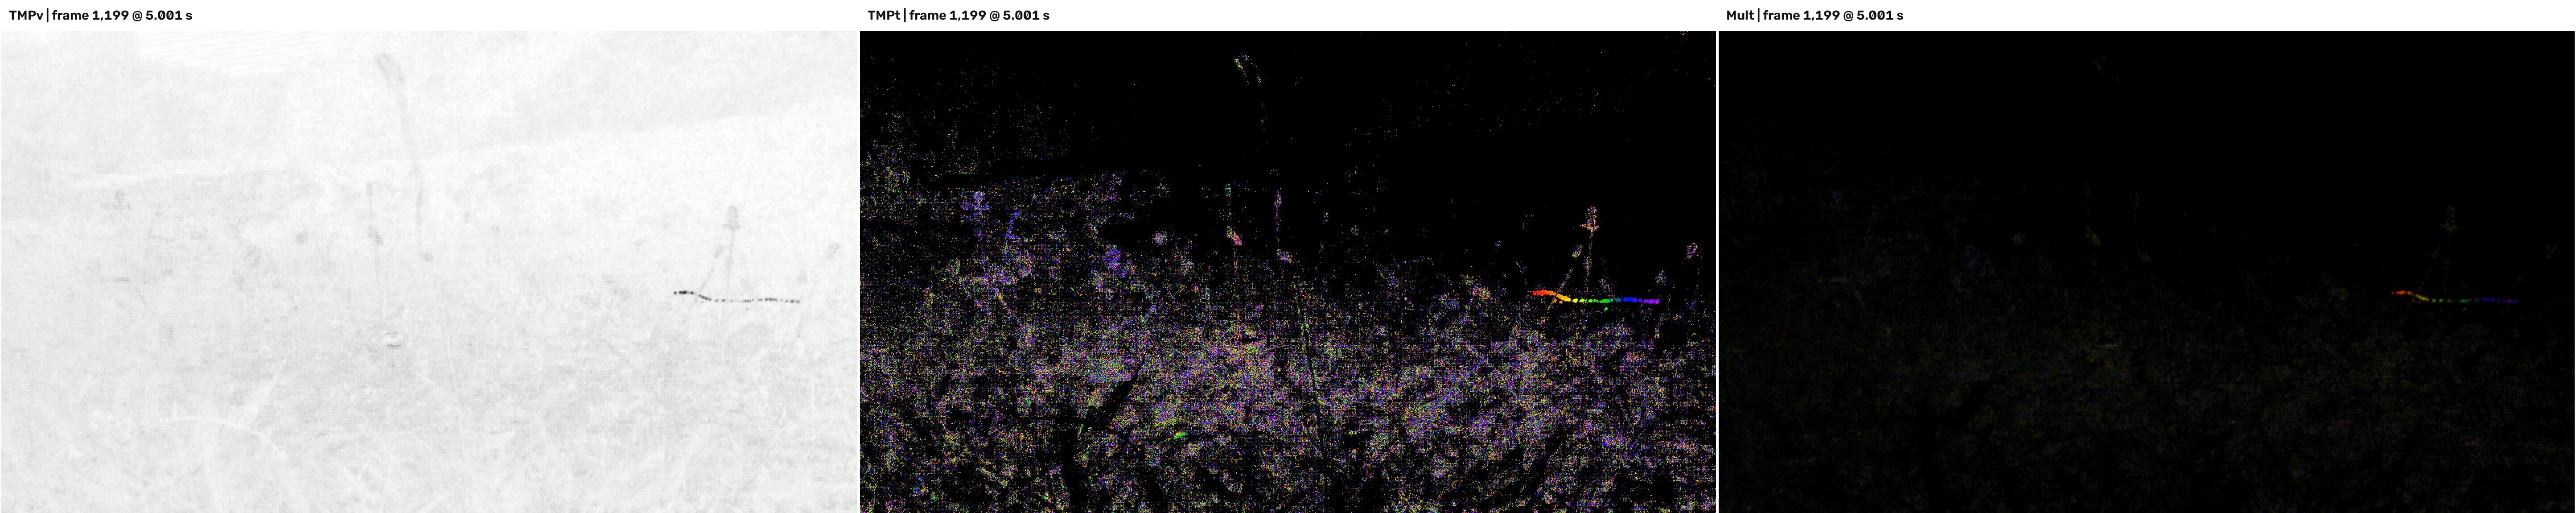

In [13]:
panels = []
for row in extraction_rows:
    name = row["representation"]
    # Convert RGB back to BGR for OpenCV drawing and JPEG encoding.
    bgr = cv2.cvtColor(frames[name], cv2.COLOR_RGB2BGR)
    # Add a white strip above the frame for its label.
    panel = cv2.copyMakeBorder(bgr, 70, 0, 3, 3, cv2.BORDER_CONSTANT, value=(255, 255, 255))
    label = f"{name} | frame {row['frame_index']:,} @ {row['nominal_time_s']:.3f} s"
    cv2.putText(panel, label, (20, 44), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (20, 20, 20), 2, cv2.LINE_AA)
    panels.append(panel)
# Join the three labeled frames and encode the result for inline display.
comparison = cv2.hconcat(panels)
ok, encoded = cv2.imencode(".jpg", comparison, [cv2.IMWRITE_JPEG_QUALITY, 92])
if not ok:
    raise RuntimeError("Could not encode comparison image")
display(Image(data=encoded.tobytes(), width=1400))


## Interpretation

- **TMPv** emphasizes strong spatial motion responses.
- **TMPt** encodes temporal progression along a trail.
- **Mult** combines the two cues and can suppress responses strong in only one representation.
- If the synchronization table passes, the three streams can be stacked by frame index(True)
- Inspect the side-by-side frame for a common trail/event. For a strict “perfect synchronization” claim, repeat at several times or validate shared source timecodes.